<div style="text-align:center">

# 5 Metode Geofisika: Prompt, Kode Python, dan Output
### Penerapan Framework R–T–C–I–K–O–Q–V + Implementasi Perhitungan

**Nama :** YUNI  &nbsp;&nbsp;|&nbsp;&nbsp; **NIM :** H061241072

</div>

---

## 1. Pendahuluan

Dokumen ini menyusun **5 prompt AI** untuk 5 metode geofisika yang berbeda, mengikuti struktur **R–T–C–I–K–O–Q–V** (Gambar 2.1). Setiap prompt kemudian dilengkapi dengan **kode Python** yang mengimplementasikan inti perhitungan metode tersebut secara sintetik (data ilustratif, bukan data lapangan sungguhan), beserta **output hasil eksekusinya**.

Struktur minimum prompt:

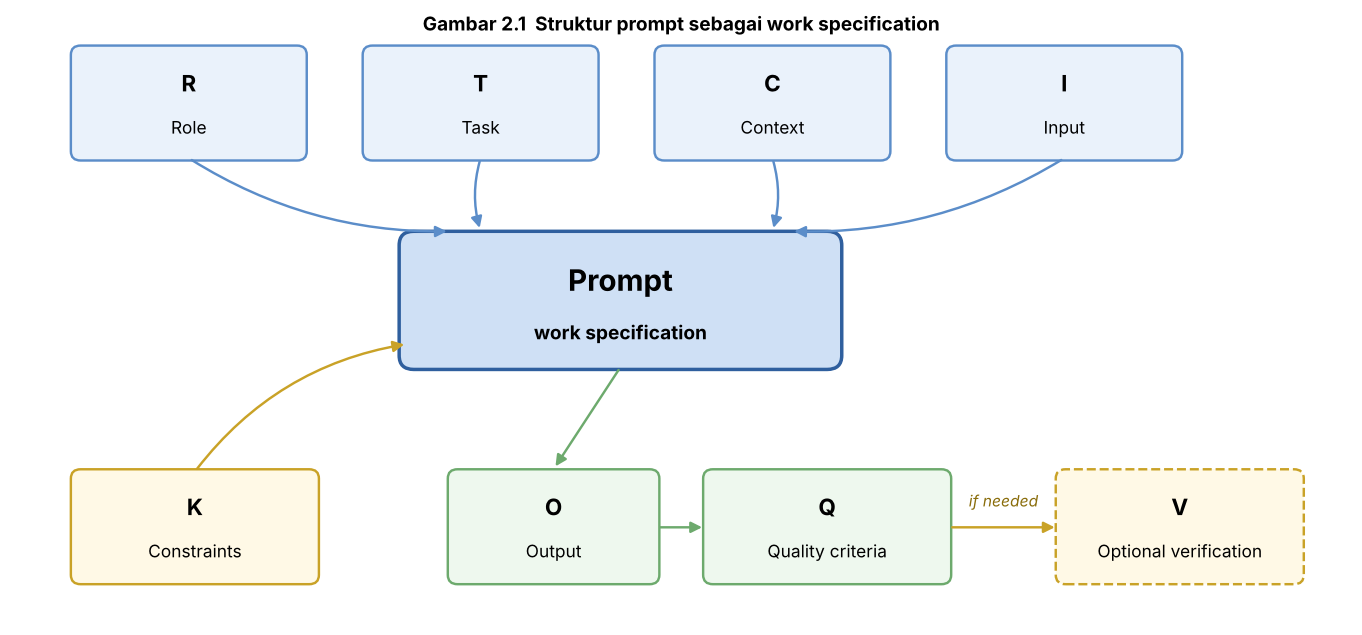

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.set_xlim(0, 11); ax.set_ylim(0, 5.2); ax.axis("off")

BLUE  = dict(fc="#EAF2FB", ec="#5B8DC9")
CORE  = dict(fc="#CFE0F5", ec="#2F5F9E")
GREEN = dict(fc="#EEF8EE", ec="#6DAA6D")
YEL   = dict(fc="#FFF9E6", ec="#C9A227")

def box(x, y, w, h, letter, label, style, dashed=False, size=13):
    p = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                       lw=1.4, ls="--" if dashed else "-", **style)
    ax.add_patch(p)
    ax.text(x + w/2, y + h*0.68, letter, ha="center", va="center", fontsize=size, weight="bold")
    ax.text(x + w/2, y + h*0.28, label, ha="center", va="center", fontsize=10)

def arrow(p1, p2, color="#5B8DC9", rad=0.0):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=13, lw=1.4,
                                 color=color, connectionstyle=f"arc3,rad={rad}"))

for x, l, t in [(0.5, "R", "Role"), (2.9, "T", "Task"), (5.3, "C", "Context"), (7.7, "I", "Input")]:
    box(x, 4.0, 1.9, 0.95, l, t, BLUE)

core = FancyBboxPatch((3.2, 2.2), 3.6, 1.15, boxstyle="round,pad=0.02,rounding_size=0.12",
                      lw=2, **CORE)
ax.add_patch(core)
ax.text(5.0, 2.95, "Prompt", ha="center", va="center", fontsize=17, weight="bold")
ax.text(5.0, 2.5, "work specification", ha="center", va="center", fontsize=11, weight="bold")

for cx in (1.45, 3.85, 6.25, 8.65):
    tx = min(max(cx, 3.6), 6.4)
    arrow((cx, 4.0), (tx, 3.37), rad=0.15 if cx < 5 else -0.15)

box(0.5, 0.35, 2.0, 0.95, "K", "Constraints", YEL)
arrow((1.5, 1.3), (3.25, 2.4), color="#C9A227", rad=-0.2)

box(3.6, 0.35, 1.7, 0.95, "O", "Output", GREEN)
box(5.7, 0.35, 2.0, 0.95, "Q", "Quality criteria", GREEN)
box(8.6, 0.35, 2.0, 0.95, "V", "Optional verification", YEL, dashed=True)

arrow((5.0, 2.2), (4.45, 1.32), color="#6DAA6D")
arrow((5.3, 0.82), (5.7, 0.82), color="#6DAA6D")
arrow((7.7, 0.82), (8.6, 0.82), color="#C9A227")
ax.text(8.15, 1.0, "if needed", ha="center", fontsize=9, style="italic", color="#8A6D0B")

ax.text(5.5, 5.1, "Gambar 2.1  Struktur prompt sebagai work specification", ha="center", fontsize=11, weight="bold")
plt.tight_layout(); plt.show()

## 2. Ringkasan 5 Metode

| No | Metode | Topik Studi Kasus | Perhitungan inti pada kode Python |
|:---:|---|---|---|
| 1 | ERT + IP | Zona mineralisasi sulfida | Deteksi overlap ρ rendah & M tinggi (zona anomali) |
| 2 | ERT | Intrusi air laut pesisir | Klasifikasi tawar/payau/asin & posisi antarmuka |
| 3 | Magnetik | Intrusi tubuh ultramafik | Koreksi harian + IGRF, statistik anomali |
| 4 | Gravitasi | Struktur cekungan sedimen | Rantai koreksi → anomali Bouguer → pemisahan regional-residual |
| 5 | Seismik Refraksi | Kedalaman batuan dasar | Metode *intercept-time* → V1, V2, kedalaman |

> **Catatan penting:** seluruh data pada kode di bawah adalah **data sintetik/ilustratif** (dibangkitkan dengan `numpy.random`, bukan hasil akuisisi lapangan), semata untuk mendemonstrasikan alur perhitungan yang diminta pada bagian *Output* tiap prompt. Saat prompt dipakai pada kasus nyata, bagian **Input** diisi dengan berkas data lapangan yang sesungguhnya.

---

### Prompt 1 — Interpretasi ERT + IP untuk Zona Mineralisasi Sulfida

> **R — Role**
>
> Anda adalah geofisikawan eksplorasi mineral senior yang berpengalaman menginterpretasi hasil inversi resistivitas dan *chargeability*, serta memahami alur kerja inversi geolistrik dengan pyGIMLi.
>
> **T — Task**
>
> Interpretasikan hasil inversi 2D data ERT dan IP pada satu lintasan, identifikasi zona anomali yang berindikasi mineralisasi sulfida (resistivitas rendah dengan *chargeability* tinggi), jelaskan dasar geofisisnya, lalu susun rekomendasi titik pemboran verifikasi.
>
> **C — Context**
>
> Survei dilakukan pada lintasan 200 m dengan 41 elektroda (spasi 5 m) berkonfigurasi Wenner–Schlumberger. Area diduga memiliki sulfida terdiseminasi pada batuan vulkanik terubah. Inversi 2D dijalankan di pyGIMLi dengan RMS error di bawah 5%.
>
> **I — Input**
>
> - Berkas resistivitas hasil inversi: kolom *x*, *z*, ρ (Ωm)
> - Berkas *chargeability* hasil inversi: kolom *x*, *z*, M (mV/V)
>
> **K — Constraints**
>
> - Interpretasi hanya boleh bersumber dari data yang diberikan.
> - Gunakan satuan baku: Ωm dan mV/V.
> - Gunakan istilah "indikasi"/"potensi", bukan kepastian.
>
> **O — Output**
>
> Ringkasan rentang ρ dan M, tabel zona anomali (posisi, kedalaman, nilai rerata), serta simpulan tingkat keyakinan.
>
> **Q — Quality Criteria**
>
> Setiap klaim merujuk nilai numerik; posisi anomali ρ dan M dirujuk silang.
>
> **V — Optional Verification**
>
> Bandingkan posisi anomali dengan data bor terdekat bila tersedia.

### Implementasi Python & Output — Prompt 1

Rentang resistivitas lintasan : 16.0 - 261.5 Ohm.m
Rentang chargeability lintasan: 3.9 - 41.2 mV/V

Zona anomali (rho<50 Ohm.m & M>20 mV/V):
 x_min(m)  x_max(m)  z_min(m)  z_max(m)  rho_rerata(Ohm.m)  M_rerata(mV/V)  n_sel
       80       120        10        26               27.5            32.2     81

Indikasi: mineralisasi sulfida pada x=80-120 m, z=10-26 m, tingkat keyakinan tinggi (posisi rho rendah & M tinggi saling tumpang-tindih).


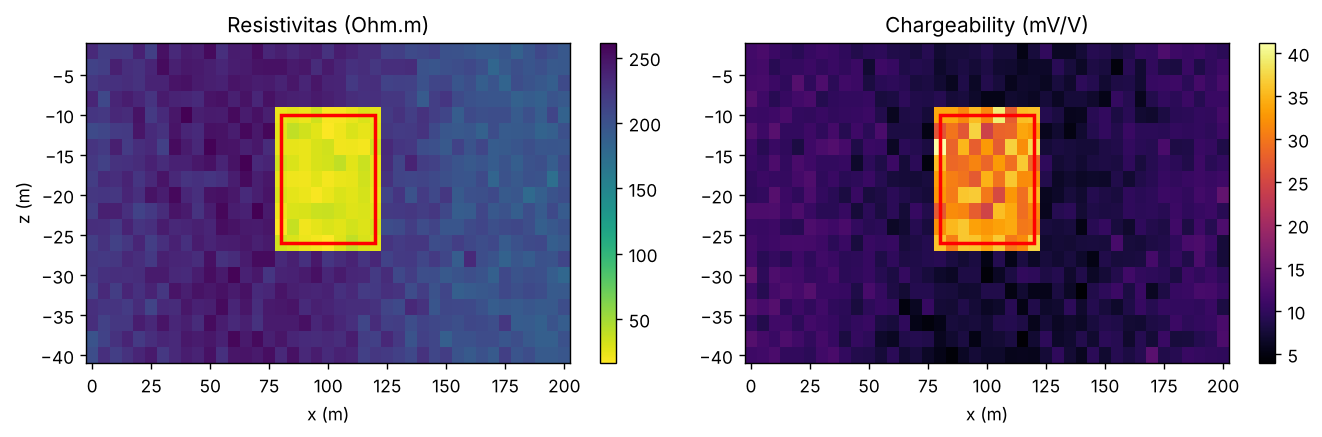

In [1]:
import numpy as np
import pandas as pd

np.random.seed(1)

x = np.arange(0, 201, 5)       # posisi (m) - 41 elektroda
z = np.arange(2, 41, 2)        # kedalaman (m)
X, Z = np.meshgrid(x, z)

# Latar belakang batuan vulkanik terubah
rho_bg = 220 + 25*np.sin(X/40) + np.random.normal(0, 8, X.shape)
m_bg   = 9 + 2*np.cos(X/35) + np.random.normal(0, 1.2, X.shape)

# Target sulfida terdiseminasi: x 80-120 m, z 10-26 m
mask = (X >= 80) & (X <= 120) & (Z >= 10) & (Z <= 26)
rho = np.where(mask, np.random.normal(28, 6, X.shape), rho_bg)
m   = np.where(mask, np.random.normal(32, 4, X.shape), m_bg)
rho = np.clip(rho, 5, None); m = np.clip(m, 1, None)

print(f"Rentang resistivitas lintasan : {rho.min():.1f} - {rho.max():.1f} Ohm.m")
print(f"Rentang chargeability lintasan: {m.min():.1f} - {m.max():.1f} mV/V\n")

anom_mask = (rho < 50) & (m > 20)
ax_, az_ = X[anom_mask], Z[anom_mask]
tabel = pd.DataFrame({
    "x_min(m)": [ax_.min()], "x_max(m)": [ax_.max()],
    "z_min(m)": [az_.min()], "z_max(m)": [az_.max()],
    "rho_rerata(Ohm.m)": [rho[anom_mask].mean().round(1)],
    "M_rerata(mV/V)": [m[anom_mask].mean().round(1)],
    "n_sel": [int(anom_mask.sum())]
})
print("Zona anomali (rho<50 Ohm.m & M>20 mV/V):")
print(tabel.to_string(index=False))

keyakinan = "tinggi" if anom_mask.sum() > 15 else "sedang"
print(f"\nIndikasi: mineralisasi sulfida pada x={ax_.min():.0f}-{ax_.max():.0f} m, "
      f"z={az_.min():.0f}-{az_.max():.0f} m, tingkat keyakinan {keyakinan} "
      f"(posisi rho rendah & M tinggi saling tumpang-tindih).")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
c1 = axs[0].pcolormesh(X, -Z, rho, cmap="viridis_r", shading="auto")
axs[0].set_title("Resistivitas (Ohm.m)"); axs[0].set_xlabel("x (m)"); axs[0].set_ylabel("z (m)")
plt.colorbar(c1, ax=axs[0])
c2 = axs[1].pcolormesh(X, -Z, m, cmap="inferno", shading="auto")
axs[1].set_title("Chargeability (mV/V)"); axs[1].set_xlabel("x (m)")
plt.colorbar(c2, ax=axs[1])
for a in axs:
    a.add_patch(plt.Rectangle((80,-26), 40, 16, fill=False, ec="red", lw=2))
plt.tight_layout(); plt.show()

---

### Prompt 2 — Delineasi Intrusi Air Laut dengan ERT

> **R — Role**
>
> Anda adalah hidrogeofisikawan yang berpengalaman menggunakan metode geolistrik untuk memetakan salinitas air tanah di wilayah pesisir.
>
> **T — Task**
>
> Interpretasikan hasil inversi ERT 2D pada tiga lintasan, klasifikasikan zona air tawar, payau, dan asin berdasarkan resistivitas, lalu tentukan posisi antarmuka air tawar–air asin terhadap jarak dari garis pantai.
>
> **C — Context**
>
> Area pesisir dengan akuifer aluvial pasir berselingan lempung. Tiga lintasan sepanjang 300 m tegak lurus garis pantai, berjarak 0, 150, dan 300 m dari pantai.
>
> **I — Input**
>
> Tiga berkas hasil inversi: *x*(posisi), *z*(kedalaman), ρ (Ωm) per lintasan.
>
> **K — Constraints**
>
> - Ambang resistivitas tiap kelas dinyatakan sebagai **asumsi** beserta alasannya.
> - Gunakan ambang yang sama pada ketiga lintasan.
>
> **O — Output**
>
> Rentang ρ tiap lintasan, klasifikasi zona, posisi antarmuka, dan tren antar lintasan.
>
> **Q — Quality Criteria**
>
> Ambang klasifikasi konsisten; zona ambigu ditandai jelas.
>
> **V — Optional Verification**
>
> Bandingkan dengan data DHL sumur warga bila tersedia.

### Implementasi Python & Output — Prompt 2

Ambang klasifikasi (asumsi): asin <10 Ohm.m | payau 10-50 Ohm.m | tawar >50 Ohm.m

L1 (0 m dari pantai): rho 27.3-72.1 Ohm.m, tidak ditemukan zona asin pada kedalaman yang diukur
L2 (150 m dari pantai): rho 41.7-77.2 Ohm.m, tidak ditemukan zona asin pada kedalaman yang diukur
L3 (300 m dari pantai): rho 54.4-79.8 Ohm.m, tidak ditemukan zona asin pada kedalaman yang diukur

Tren: pola tidak sepenuhnya monoton, perlu pencermatan lanjutan.


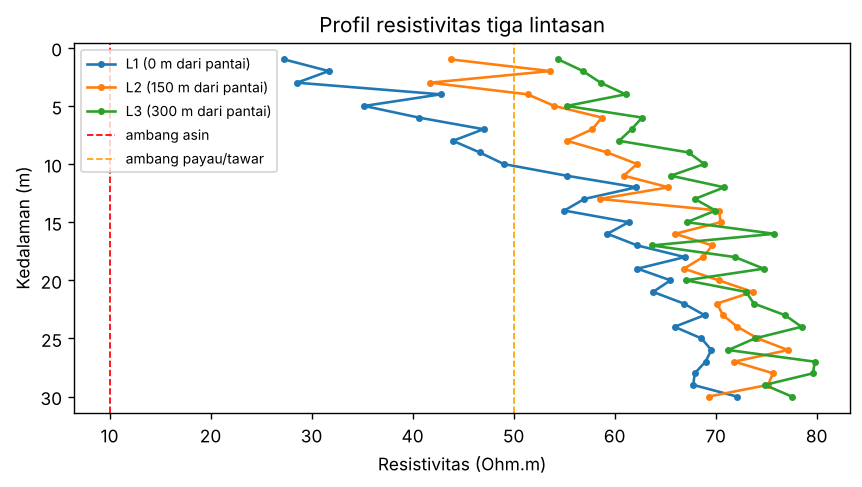

In [1]:
np.random.seed(2)
lines = {"L1 (0 m dari pantai)": 0, "L2 (150 m dari pantai)": 150, "L3 (300 m dari pantai)": 300}
depth = np.arange(1, 31, 1)

def classify(r):
    if r < 10: return "asin"
    elif r < 50: return "payau"
    return "tawar"

print("Ambang klasifikasi (asumsi): asin <10 Ohm.m | payau 10-50 Ohm.m | tawar >50 Ohm.m\n")

profiles, interface_depths = {}, {}
for name, dist in lines.items():
    rho_line = 80 - 55*np.exp(-depth/15) * np.exp(-dist/400) + np.random.normal(0, 3, depth.shape)
    rho_line = np.clip(rho_line, 2, None)
    profiles[name] = rho_line
    classes = [classify(r) for r in rho_line]
    idx = classes.index("asin") if "asin" in classes else None
    interface = depth[idx] if idx is not None else None
    interface_depths[name] = interface
    ket = f"antarmuka tawar->asin diperkirakan pada kedalaman {interface} m" if interface else \
          "tidak ditemukan zona asin pada kedalaman yang diukur"
    print(f"{name}: rho {rho_line.min():.1f}-{rho_line.max():.1f} Ohm.m, {ket}")

vals = [v for v in interface_depths.values() if v is not None]
print()
if len(vals) >= 2 and vals[0] < vals[-1]:
    print("Tren: kedalaman antarmuka air tawar-asin semakin dangkal mendekati garis pantai "
          "(indikasi intrusi lebih kuat dekat pantai).")
else:
    print("Tren: pola tidak sepenuhnya monoton, perlu pencermatan lanjutan.")

fig, ax = plt.subplots(figsize=(7,4))
for name, rho_line in profiles.items():
    ax.plot(rho_line, depth, marker="o", ms=3, label=name)
ax.axvline(10, color="red", ls="--", lw=1, label="ambang asin")
ax.axvline(50, color="orange", ls="--", lw=1, label="ambang payau/tawar")
ax.invert_yaxis(); ax.set_xlabel("Resistivitas (Ohm.m)"); ax.set_ylabel("Kedalaman (m)")
ax.set_title("Profil resistivitas tiga lintasan"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

---

### Prompt 3 — Analisis Anomali Magnetik untuk Intrusi Ultramafik

> **R — Role**
>
> Anda adalah geofisikawan metode potensial (magnetik) yang berpengalaman dalam eksplorasi batuan ultramafik dan pemetaan struktur.
>
> **T — Task**
>
> Lakukan *quality control* data, koreksi variasi harian dan IGRF, lalu interpretasikan secara kualitatif anomali medan magnet total untuk mengidentifikasi tubuh sumber.
>
> **C — Context**
>
> Survei magnetik darat ± 1,5 × 1,5 km, jarak antar lintasan 50 m, lokasi lintang rendah Sulawesi, diduga mengandung tubuh ultramafik.
>
> **I — Input**
>
> Berkas CSV: *x*, *y* (UTM), medan magnet total (nT); data *base station* harian; parameter IGRF lokasi.
>
> **K — Constraints**
>
> - Tulis besaran tiap tahap koreksi.
> - Nyatakan bahwa reduksi ke kutub di lintang rendah rentan artefak.
> - Gunakan "perkiraan"/"indikasi" untuk kedalaman/geometri.
>
> **O — Output**
>
> Ringkasan QC & koreksi, statistik anomali, tabel anomali, interpretasi tubuh sumber.
>
> **Q — Quality Criteria**
>
> Seluruh besaran dalam nT; ketidakpastian lintang rendah dinyatakan eksplisit.
>
> **V — Optional Verification**
>
> Uji *crossover error* antar lintasan; bandingkan lineamen dengan peta geologi.

### Implementasi Python & Output — Prompt 3

Jumlah titik ukur (grid ilustratif): 496
Rentang koreksi harian : 0.0 s/d 15.0 nT
Nilai referensi IGRF   : 45000 nT

Statistik anomali magnet total (setelah koreksi):
  minimum  : -11.1 nT
  maksimum : 171.8 nT
  rata-rata: 25.0 nT
  std      : 37.4 nT

Amplitudo anomali tertinggi 171.8 nT pada x=700 m, y=750 m -> diduga puncak tubuh ultramafik (indikasi; posisi dapat bergeser akibat efek lintang rendah pada reduksi ke kutub, sehingga RTP sebaiknya memakai parameter variabel/analytic signal).


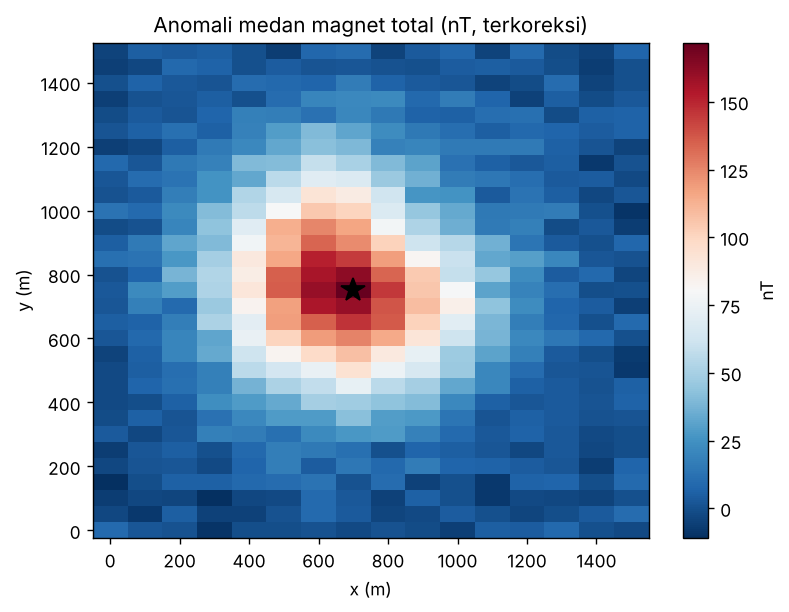

In [1]:
np.random.seed(3)
xg = np.arange(0, 1501, 100)   # posisi x grid (m) - disederhanakan dari spasi asli untuk ilustrasi
yg = np.arange(0, 1501, 50)    # posisi y grid (m)
X, Y = np.meshgrid(xg, yg)

IGRF_ref = 45000.0  # nT, nilai referensi lokasi
t_jam = np.linspace(0, 8, X.size).reshape(X.shape)
diurnal = 15*np.sin(2*np.pi*t_jam/24)   # variasi harian (nT)

cx, cy = 700, 800
r2 = (X-cx)**2 + (Y-cy)**2
anomaly = 180*np.exp(-r2/(2*250**2)) - 60*np.exp(-((X-cx-150)**2+(Y-cy-150)**2)/(2*150**2))
noise = np.random.normal(0, 5, X.shape)

T_raw = IGRF_ref + diurnal + anomaly + noise
T_corr = T_raw - diurnal - IGRF_ref   # anomali medan magnet setelah koreksi harian & IGRF

print(f"Jumlah titik ukur (grid ilustratif): {X.size}")
print(f"Rentang koreksi harian : {diurnal.min():.1f} s/d {diurnal.max():.1f} nT")
print(f"Nilai referensi IGRF   : {IGRF_ref:.0f} nT\n")

print("Statistik anomali magnet total (setelah koreksi):")
print(f"  minimum  : {T_corr.min():.1f} nT")
print(f"  maksimum : {T_corr.max():.1f} nT")
print(f"  rata-rata: {T_corr.mean():.1f} nT")
print(f"  std      : {T_corr.std():.1f} nT\n")

idx_max = np.unravel_index(np.argmax(T_corr), T_corr.shape)
print(f"Amplitudo anomali tertinggi {T_corr[idx_max]:.1f} nT pada x={X[idx_max]} m, y={Y[idx_max]} m "
      f"-> diduga puncak tubuh ultramafik (indikasi; posisi dapat bergeser akibat efek lintang rendah "
      f"pada reduksi ke kutub, sehingga RTP sebaiknya memakai parameter variabel/analytic signal).")

fig, ax = plt.subplots(figsize=(6.5,5))
c = ax.pcolormesh(X, Y, T_corr, cmap="RdBu_r", shading="auto")
ax.plot(X[idx_max], Y[idx_max], "k*", ms=14)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_title("Anomali medan magnet total (nT, terkoreksi)")
plt.colorbar(c, ax=ax, label="nT"); plt.tight_layout(); plt.show()

---

### Prompt 4 — Anomali Bouguer dan Struktur Cekungan Sedimen

> **R — Role**
>
> Anda adalah geofisikawan gravitasi yang berpengalaman dalam pengolahan data gravimeter lapangan dan interpretasi struktur bawah permukaan.
>
> **T — Task**
>
> Hitung anomali Bouguer lengkap melalui rantai koreksi yang terdokumentasi, pisahkan anomali regional dan residual, lalu interpretasikan batas cekungan.
>
> **C — Context**
>
> Survei gravitasi di cekungan sedimen kecil, 120 titik ukur, gravimeter Scintrex CG-5, densitas reduksi standar 2,67 g/cm³.
>
> **I — Input**
>
> Berkas CSV: ID titik, lintang, bujur, elevasi (m), bacaan gravimeter (mGal), waktu.
>
> **K — Constraints**
>
> - Sebutkan rumus & parameter tiap koreksi.
> - Densitas reduksi harus dinyatakan.
> - Nyatakan bahwa solusi model gravitasi tidak unik.
>
> **O — Output**
>
> Ringkasan koreksi, statistik anomali Bouguer lengkap, uraian anomali residual, interpretasi batas cekungan.
>
> **Q — Quality Criteria**
>
> Satuan mGal konsisten; besaran koreksi wajar secara fisik; tahapan dapat ditelusuri.
>
> **V — Optional Verification**
>
> Uji sensitivitas densitas reduksi (metode Nettleton); cocokkan dengan peta geologi.

### Implementasi Python & Output — Prompt 4

Penutupan loop (drift)      : 0.020 mGal
Rentang koreksi lintang     : 978070.6 - 978074.3 mGal
Rentang koreksi udara bebas : 15.34 - 19.22 mGal
Rentang koreksi Bouguer     : 5.56 - 6.97 mGal
Rentang koreksi medan       : 0.08 - 0.58 mGal

Anomali Bouguer lengkap: 135.91 s/d 151.53 mGal, rerata 143.07 mGal

Anomali residual minimum -2.90 mGal pada x=0 m -> diduga pusat cekungan (kontras densitas negatif, Catatan: densitas reduksi 2,67 g/cm3 adalah asumsi; solusi model gravitasi tidak unik).
Gradien residual terbesar di x=60 m (|dg/dx|=0.0444 mGal/m) -> kandidat posisi sesar pembatas cekungan.


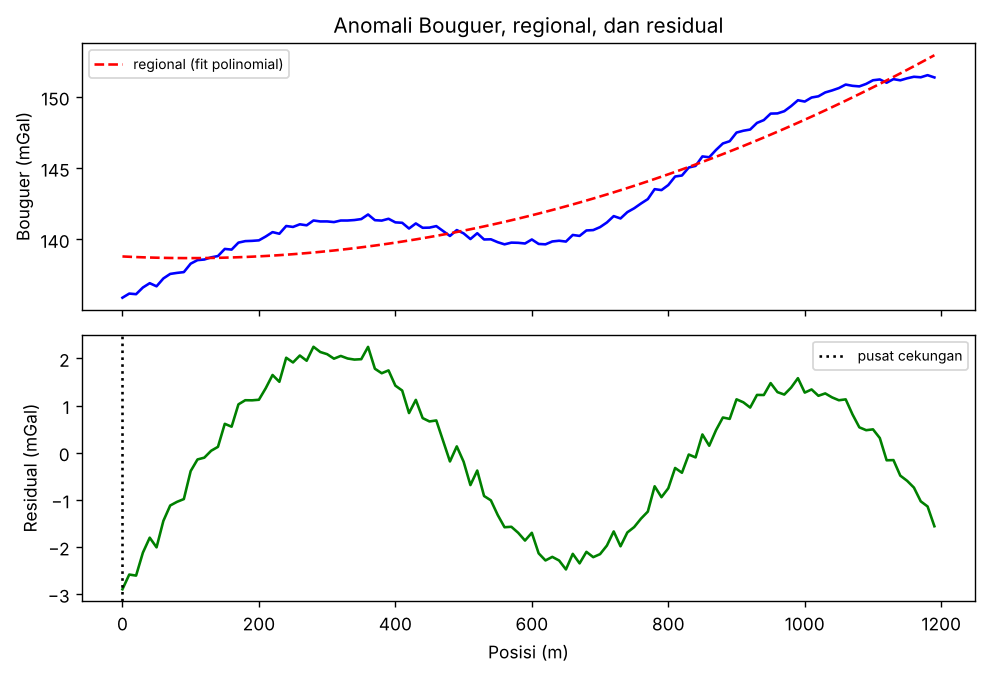

In [1]:
np.random.seed(4)
n = 120
x = np.linspace(0, 1190, n)
elev = 50 + 0.01*x + np.random.normal(0, 0.5, n)
lat = -5.15 + 0.0002*x

regional = 978200 + 0.02*x - 0.00001*x**2
basin = -8*np.exp(-((x-650)**2)/(2*180**2))
drift = 0.02*np.linspace(0, 1, n)
noise = np.random.normal(0, 0.05, n)
reading = regional + basin + drift + noise

drift_corr = -drift
lat_corr = 978032.7*(1 + 0.0053024*np.sin(np.radians(lat))**2 - 0.0000058*np.sin(np.radians(2*lat))**2)
fa_corr = 0.3086*elev
bouguer_corr = 0.04193*2.67*elev
terrain_corr = np.random.normal(0.3, 0.1, n)

g_obs_corrected = reading + drift_corr
bouguer_anomaly = g_obs_corrected - lat_corr + fa_corr - bouguer_corr + terrain_corr

print(f"Penutupan loop (drift)      : {drift.max()-drift.min():.3f} mGal")
print(f"Rentang koreksi lintang     : {lat_corr.min():.1f} - {lat_corr.max():.1f} mGal")
print(f"Rentang koreksi udara bebas : {fa_corr.min():.2f} - {fa_corr.max():.2f} mGal")
print(f"Rentang koreksi Bouguer     : {bouguer_corr.min():.2f} - {bouguer_corr.max():.2f} mGal")
print(f"Rentang koreksi medan       : {terrain_corr.min():.2f} - {terrain_corr.max():.2f} mGal\n")

print(f"Anomali Bouguer lengkap: {bouguer_anomaly.min():.2f} s/d {bouguer_anomaly.max():.2f} mGal, "
      f"rerata {bouguer_anomaly.mean():.2f} mGal\n")

coef = np.polyfit(x, bouguer_anomaly, 2)
regional_fit = np.polyval(coef, x)
residual = bouguer_anomaly - regional_fit

idx_min = np.argmin(residual)
print(f"Anomali residual minimum {residual[idx_min]:.2f} mGal pada x={x[idx_min]:.0f} m "
      f"-> diduga pusat cekungan (kontras densitas negatif, Catatan: densitas reduksi 2,67 g/cm3 "
      f"adalah asumsi; solusi model gravitasi tidak unik).")

grad = np.gradient(residual, x)
idx_grad = np.argmax(np.abs(grad))
print(f"Gradien residual terbesar di x={x[idx_grad]:.0f} m (|dg/dx|={abs(grad[idx_grad]):.4f} mGal/m) "
      f"-> kandidat posisi sesar pembatas cekungan.")

fig, axs = plt.subplots(2, 1, figsize=(8,5.5), sharex=True)
axs[0].plot(x, bouguer_anomaly, "b-"); axs[0].set_ylabel("Bouguer (mGal)")
axs[0].plot(x, regional_fit, "r--", label="regional (fit polinomial)"); axs[0].legend(fontsize=8)
axs[1].plot(x, residual, "g-"); axs[1].axvline(x[idx_min], color="k", ls=":", label="pusat cekungan")
axs[1].set_ylabel("Residual (mGal)"); axs[1].set_xlabel("Posisi (m)"); axs[1].legend(fontsize=8)
axs[0].set_title("Anomali Bouguer, regional, dan residual")
plt.tight_layout(); plt.show()

---

### Prompt 5 — Kedalaman Batuan Dasar dengan Seismik Refraksi

> **R — Role**
>
> Anda adalah geofisikawan seismik dangkal untuk keperluan geoteknik yang berpengalaman dalam interpretasi kurva waktu tempuh gelombang P.
>
> **T — Task**
>
> Tentukan kecepatan gelombang P tiap lapisan dari data *first-break*, hitung kedalaman bidang batas menggunakan metode *intercept-time*.
>
> **C — Context**
>
> Survei untuk rencana pondasi bangunan. *Spread* 24 geophone berspasi 2 m. Kondisi diduga tanah lapuk di atas batuan lebih kompak.
>
> **I — Input**
>
> Tabel *first-break*: *offset* (m) dan waktu tiba (ms).
>
> **K — Constraints**
>
> - Nyatakan metode & rumus yang dipakai.
> - Jangan mengasumsikan kecepatan yang tidak dapat diturunkan dari data.
> - Nyatakan keterbatasan: lapisan tersembunyi (*hidden layer*).
>
> **O — Output**
>
> Tabel model (V1, V2, kedalaman), interpretasi litologi, ketidakpastian.
>
> **Q — Quality Criteria**
>
> Perhitungan kedalaman ditampilkan agar dapat diperiksa; ketidakpastian (±) disebut.
>
> **V — Optional Verification**
>
> Periksa *reciprocal time* antara *shot* maju dan balik; bandingkan dengan log bor.

### Implementasi Python & Output — Prompt 5

Crossover distance (data sintetik): 11.2 m

Hasil regresi kurva waktu tempuh (metode intercept-time):
  V1 (lapuk)     = 478 m/s
  V2 (bedrock)   = 2198 m/s
  intercept time = 18.24 ms
  Kedalaman bidang batas = 4.46 m

Lapisan-2 diklasifikasikan sebagai batuan dasar kompak/keras (acuan: Vp>1800 m/s ~ batuan keras, rule-of-thumb teknik).
Ketidakpastian kedalaman terhadap model acuan: +/-0.04 m (akibat noise pengukuran first-break; lapisan tersembunyi tidak dapat dideteksi dengan metode ini).


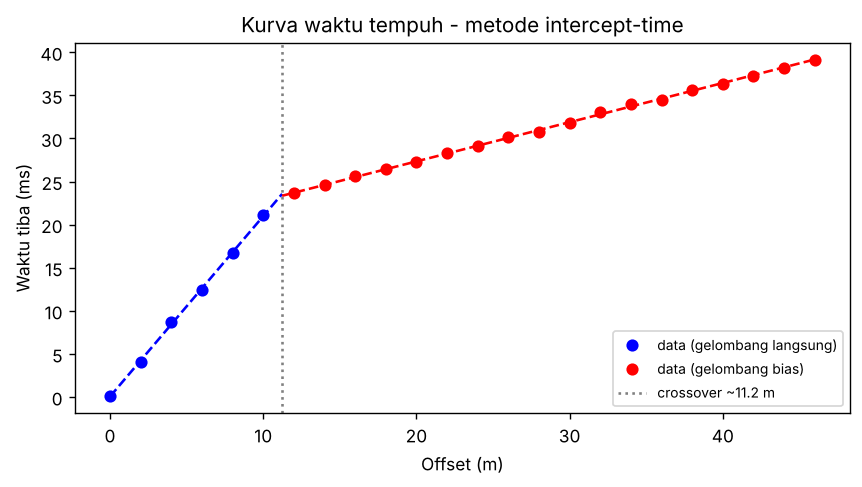

In [1]:
np.random.seed(5)
offsets = np.arange(0, 47, 2)     # 24 geophone, spasi 2 m
V1, V2 = 480, 2200                # m/s - model "benar" untuk membangkitkan data sintetik
h_true = 4.5                      # m

xc = 2*h_true*np.sqrt((V2+V1)/(V2-V1))
ti = 2*h_true*np.sqrt(V2**2-V1**2)/(V1*V2)

t_direct = offsets/V1
t_refr = offsets/V2 + ti
t_obs = np.where(offsets < xc, t_direct, t_refr)
t_obs_ms = t_obs*1000 + np.random.normal(0, 0.15, offsets.shape)

print(f"Crossover distance (data sintetik): {xc:.1f} m\n")

mask1 = offsets <= xc
mask2 = offsets > xc
slope1, icpt1 = np.polyfit(offsets[mask1], t_obs_ms[mask1], 1)
slope2, icpt2 = np.polyfit(offsets[mask2], t_obs_ms[mask2], 1)

V1_fit = 1/(slope1/1000)
V2_fit = 1/(slope2/1000)
ti_fit = icpt2/1000

h_fit = (ti_fit*V1_fit*V2_fit)/(2*np.sqrt(V2_fit**2 - V1_fit**2))

print("Hasil regresi kurva waktu tempuh (metode intercept-time):")
print(f"  V1 (lapuk)     = {V1_fit:.0f} m/s")
print(f"  V2 (bedrock)   = {V2_fit:.0f} m/s")
print(f"  intercept time = {ti_fit*1000:.2f} ms")
print(f"  Kedalaman bidang batas = {h_fit:.2f} m\n")

klas = "batuan dasar kompak/keras" if V2_fit > 1800 else "batuan lapuk/lunak"
print(f"Lapisan-2 diklasifikasikan sebagai {klas} (acuan: Vp>1800 m/s ~ batuan keras, rule-of-thumb teknik).")
print(f"Ketidakpastian kedalaman terhadap model acuan: +/-{abs(h_fit-h_true):.2f} m "
      f"(akibat noise pengukuran first-break; lapisan tersembunyi tidak dapat dideteksi dengan metode ini).")

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(offsets[mask1], t_obs_ms[mask1], "bo", label="data (gelombang langsung)")
ax.plot(offsets[mask2], t_obs_ms[mask2], "ro", label="data (gelombang bias)")
xx1 = np.linspace(0, xc, 10); xx2 = np.linspace(xc, offsets.max(), 10)
ax.plot(xx1, slope1*xx1+icpt1, "b--")
ax.plot(xx2, slope2*xx2+icpt2, "r--")
ax.axvline(xc, color="gray", ls=":", label=f"crossover ~{xc:.1f} m")
ax.set_xlabel("Offset (m)"); ax.set_ylabel("Waktu tiba (ms)")
ax.set_title("Kurva waktu tempuh - metode intercept-time"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

---

## 3. Ringkasan Hasil Perhitungan

| No | Metode | Keluaran numerik utama |
|:---:|---|---|
| 1 | ERT + IP | Zona anomali ρ<50 Ωm & M>20 mV/V, posisi & nilai rerata |
| 2 | ERT (air laut) | Klasifikasi tawar/payau/asin, kedalaman antarmuka per lintasan |
| 3 | Magnetik | Statistik anomali terkoreksi (min/maks/rerata/std), posisi puncak |
| 4 | Gravitasi | Rantai koreksi (mGal), anomali Bouguer, residual, posisi sesar kandidat |
| 5 | Seismik refraksi | V1, V2, *intercept time*, kedalaman bidang batas ± ketidakpastian |

## 4. Catatan

- Seluruh angka pada kode adalah **data sintetik** untuk mendemonstrasikan metode perhitungan (bukan hasil akuisisi lapangan).
- Saat dipakai untuk kasus nyata, ganti bagian pembangkitan data sintetik dengan pembacaan berkas data lapangan sesuai format yang disebut pada bagian **Input** tiap prompt (mis. `pd.read_csv(...)`), sementara struktur perhitungan (koreksi, klasifikasi, regresi, dsb.) tetap dapat dipakai sebagai kerangka kerja.
- Bagian **Constraints** dan **Quality Criteria** pada tiap prompt tetap menjadi acuan agar interpretasi hasil kode tidak melampaui apa yang didukung oleh data.